# LMC-Based Lymph Node Metastasis Prediction and Survival Analysis

This notebook reproduces the regularized logistic regression (L1 / Elastic Net) metastasis classification and clinical survival analyses derived from latent methylation component (LMC) proportions in two representative TCGA cohorts:
- **COAD** (`cancer-specific_LMC`, Individual Cancer LMC model; *n* = 194)
- **LUAD** (`cross-cancer_LMC`, Pan-Cancer LMC model; *n* = 194)

Running all cells executes inner 5×5 repeated stratified cross-validation tuning, outer leave-one-out cross-validation (LOOCV) risk-score generation, ROC discrimination, two-sided Mann–Whitney *U* testing, Kaplan–Meier survival stratification, and univariate Cox proportional hazards regression.

## 1. Environment Setup and Data Loading

In [ ]:
# Optional: GitHub repository URL for automatic data cloning in Google Colab
GITHUB_REPO = "https://github.com/Aiorwtlky/LMC-Metastasis-Prediction"  # e.g., "https://github.com/<username>/<repo>.git"

import sys
import subprocess
import warnings
import zipfile
from pathlib import Path

try:
    import lifelines
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lifelines"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, LeaveOneOut
from sklearn.metrics import roc_curve, auc
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["axes.unicode_minus"] = False

def resolve_data_dir():
    for p in [Path("./data"), Path("./LMC_Metastasis_Prediction/data"), Path("./repo_data/data")]:
        if (p / "sample_list.tsv").exists():
            return p.resolve()

    if GITHUB_REPO.strip():
        repo_dst = Path("./repo_data")
        if not repo_dst.exists():
            print(f"Cloning repository data from {GITHUB_REPO} ...")
            subprocess.check_call(["git", "clone", "--depth", "1", GITHUB_REPO.strip(), str(repo_dst)])
        for p in [repo_dst / "data", repo_dst / "LMC_Metastasis_Prediction/data"]:
            if (p / "sample_list.tsv").exists():
                return p.resolve()

    if "google.colab" in sys.modules:
        from google.colab import files
        print("Upload the dataset archive (lmc_prediction_data.zip) to extract ./data:")
        uploaded = files.upload()
        for fname in uploaded:
            if fname.endswith(".zip"):
                with zipfile.ZipFile(fname, "r") as z:
                    z.extractall(".")
        if (Path("./data") / "sample_list.tsv").exists():
            return Path("./data").resolve()

    raise FileNotFoundError(
        "Dataset directory './data' not found. Run inside the repository directory, set GITHUB_REPO, or upload lmc_prediction_data.zip in Colab."
    )

DATA_DIR = resolve_data_dir()
print(f"Data directory ready: {DATA_DIR}")


Data directory ready: /Users/qv/Documents/Deconvolution/20261124/LMC_Metastasis_Prediction/data


## 2. Elastic Net Tuning, LOOCV, and Survival Modeling

In [2]:
MODEL_CONFIGS = {
    "Individual": {"label": "Individual Cancer LMC", "folder": "cancer-specific_LMC", "suffix": "_proportion.tsv"},
    "Pan_Cancer": {"label": "Pan-Cancer LMC", "folder": "cross-cancer_LMC", "suffix": "_proportion_array.tsv"},
}

def get_stars(p):
    if p < 0.001:
        return " ***"
    if p < 0.01:
        return " **"
    if p < 0.05:
        return " *"
    return ""

def run_cohort_evaluation(cancer, model_type):
    cfg = MODEL_CONFIGS[model_type]
    prop_df = pd.read_csv(DATA_DIR / cfg["folder"] / f"{cancer}{cfg['suffix']}", sep="\t", index_col=0).T
    prop_df.index.name = "sample_id"
    prop_df.reset_index(inplace=True)
    feature_cols = [c for c in prop_df.columns if c != "sample_id"]

    sl = pd.read_csv(DATA_DIR / "sample_list.tsv", sep="\t")
    clin_df = sl[sl["cancer_type"] == cancer].drop_duplicates(subset=["sample_id"])
    surv_df = pd.read_csv(DATA_DIR / "sample_survival" / f"{cancer}_survival.tsv", sep="\t").drop_duplicates(subset=["sample_id"])

    common_ids = set(prop_df["sample_id"]) & set(clin_df["sample_id"]) & set(surv_df["sample_id"])
    merged = (
        prop_df[prop_df["sample_id"].isin(common_ids)]
        .merge(clin_df[["sample_id", "group", "N_status"]], on="sample_id", how="inner")
        .merge(surv_df[["sample_id", "time", "censored"]], on="sample_id", how="inner")
    )
    merged = merged[merged["group"].isin(["N0", "N+"])].copy()
    merged["event_observed"] = ~merged["censored"]

    X = merged[feature_cols]
    y = (merged["group"] == "N+").astype(int)

    # Inner hyperparameter tuning (5x5 repeated stratified CV, zero data leakage)
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(solver="saga", class_weight="balanced", max_iter=10000, random_state=42)),
    ])
    param_grid = [
        {"lr__penalty": ["l1"], "lr__C": np.logspace(-3, 3, 50)},
        {"lr__penalty": ["elasticnet"], "lr__C": np.logspace(-3, 3, 20), "lr__l1_ratio": np.linspace(0.1, 0.9, 9)},
    ]
    grid = GridSearchCV(pipe, param_grid, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42),
                        scoring="roc_auc", n_jobs=-1)
    grid.fit(X, y)
    best_pipe = grid.best_estimator_

    # Outer Leave-One-Out Cross-Validation (LOOCV)
    oof_probs = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(X):
        best_pipe.fit(X.iloc[tr], y.iloc[tr])
        oof_probs[te] = best_pipe.predict_proba(X.iloc[te])[:, 1]
    merged["Risk_Score"] = oof_probs

    fpr, tpr, _ = roc_curve(y, oof_probs)
    auroc = float(auc(fpr, tpr))
    _, mw_p = mannwhitneyu(merged[merged["group"] == "N+"]["Risk_Score"],
                           merged[merged["group"] == "N0"]["Risk_Score"], alternative="two-sided")

    T, E = merged["time"], merged["event_observed"]
    med = merged["Risk_Score"].median()
    km50_p = float(logrank_test(T[merged["Risk_Score"] > med], T[merged["Risk_Score"] <= med],
                                event_observed_A=E[merged["Risk_Score"] > med],
                                event_observed_B=E[merged["Risk_Score"] <= med]).p_value)
    q67, q33 = merged["Risk_Score"].quantile(0.67), merged["Risk_Score"].quantile(0.33)
    km33_p = float(logrank_test(T[merged["Risk_Score"] > q67], T[merged["Risk_Score"] < q33],
                                event_observed_A=E[merged["Risk_Score"] > q67],
                                event_observed_B=E[merged["Risk_Score"] < q33]).p_value)

    cph = CoxPHFitter().fit(merged[["time", "event_observed", "Risk_Score"]], duration_col="time", event_col="event_observed")
    cox_p = float(cph.summary.loc["Risk_Score", "p"])
    cox_hr = float(cph.summary.loc["Risk_Score", "exp(coef)"])

    merged["Risk_Z"] = (merged["Risk_Score"] - merged["Risk_Score"].mean()) / merged["Risk_Score"].std()
    cph_z = CoxPHFitter().fit(merged[["time", "event_observed", "Risk_Z"]], duration_col="time", event_col="event_observed")
    cox_hr_sd = float(cph_z.summary.loc["Risk_Z", "exp(coef)"])

    return {
        "cancer": cancer, "model_label": cfg["label"], "merged": merged, "fpr": fpr, "tpr": tpr,
        "n0": int((merged["group"] == "N0").sum()), "np": int((merged["group"] == "N+").sum()),
        "auroc": auroc, "mw_p": float(mw_p), "km50_p": km50_p, "km33_p": km33_p,
        "cox_p": cox_p, "cox_hr": cox_hr, "cox_hr_sd": cox_hr_sd,
    }

res_coad = run_cohort_evaluation("COAD", "Individual")
res_luad = run_cohort_evaluation("LUAD", "Pan_Cancer")

pd.DataFrame([
    {
        "Model": r["model_label"], "Cancer": r["cancer"],
        "Samples (N0, N+)": f"{r['n0']}, {r['np']}", "AUROC": f"{r['auroc']:.4f}{get_stars(r['mw_p'])}",
        "Mann-Whitney P": "< 0.001 ***" if r["mw_p"] < 0.001 else f"{r['mw_p']:.4f}",
        "KM Median P (50%)": f"{r['km50_p']:.4f}{get_stars(r['km50_p'])}",
        "KM Tertile P (33%)": f"{r['km33_p']:.4f}{get_stars(r['km33_p'])}",
        "Cox P": f"{r['cox_p']:.4f}{get_stars(r['cox_p'])}",
        "Cox HR (Raw +1.0)": f"{r['cox_hr']:.2f}",
        "Cox HR (Per-SD)": f"{r['cox_hr_sd']:.2f}",
    }
    for r in [res_coad, res_luad]
])


Model,Cancer,"Samples (N0, N+)",AUROC,Mann-Whitney P,KM Median P (50%),KM Tertile P (33%),Cox P,Cox HR (Raw +1.0),Cox HR (Per-SD)
Individual Cancer LMC,COAD,"96, 98",0.7209 ***,< 0.001 ***,0.1852,0.0345 *,0.1545,2.56,1.20
Pan-Cancer LMC,LUAD,"97, 97",0.7105 ***,< 0.001 ***,0.0080 **,0.0168 *,0.0002 ***,142.56,1.59


## 3. ROC Discrimination, Risk Score Distribution, and Survival Curves

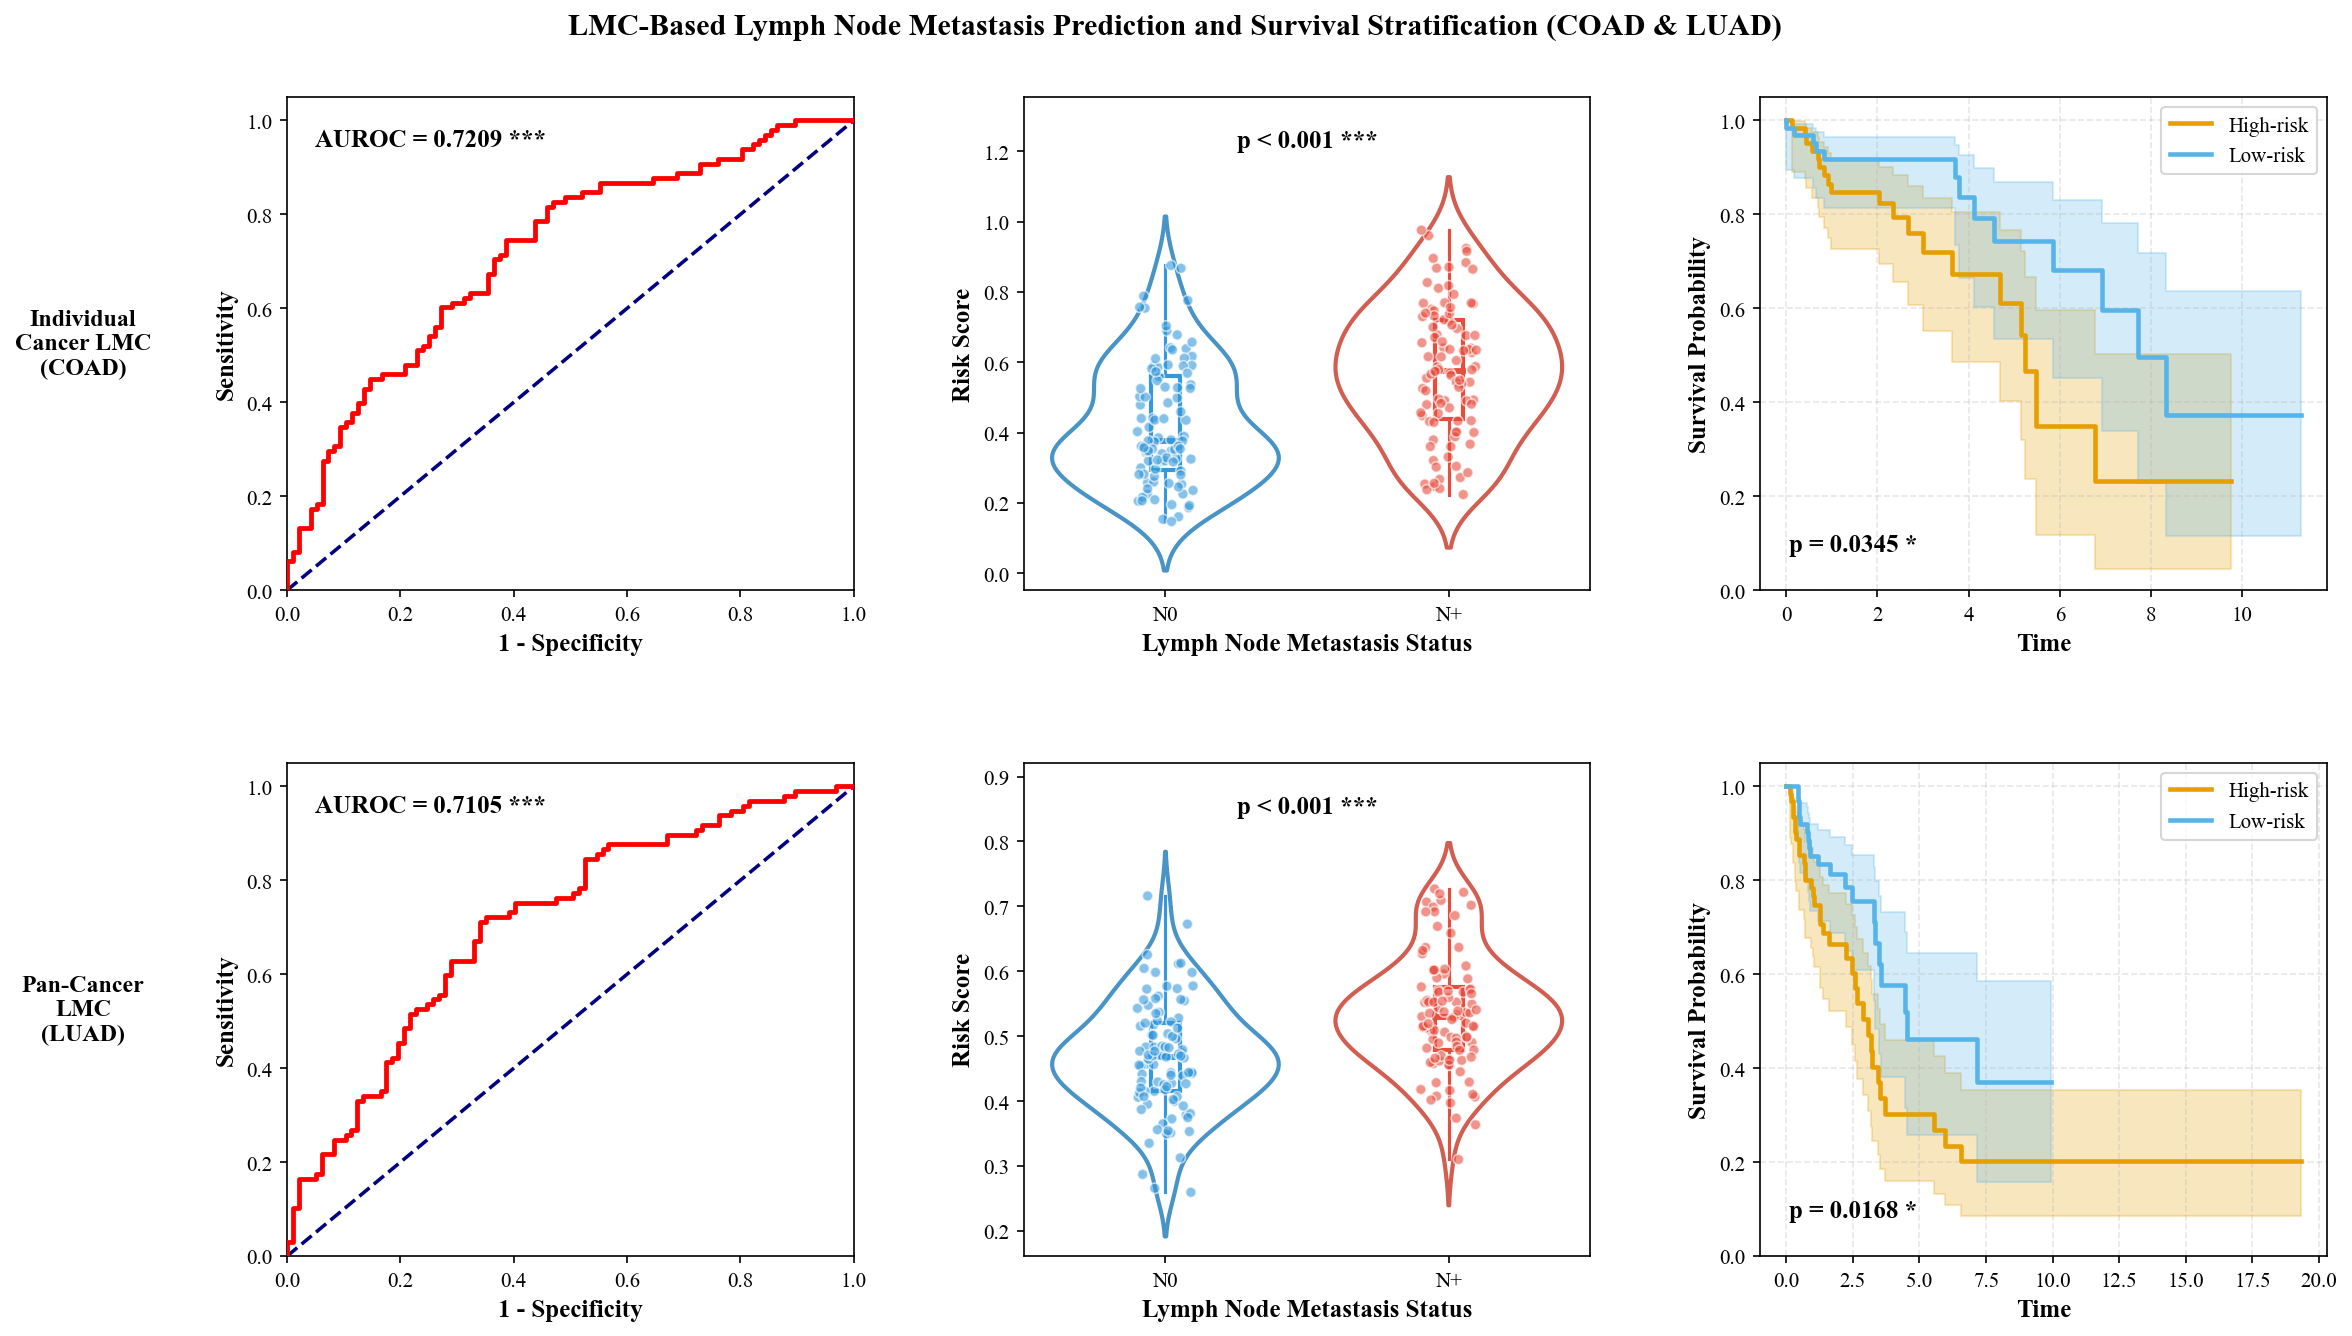

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(16.0, 9.2), dpi=160)
plt.subplots_adjust(hspace=0.35, wspace=0.30, top=0.92, bottom=0.08, left=0.13, right=0.98)

for row_idx, res in enumerate([res_coad, res_luad]):
    merged = res["merged"]
    lbl_text = res["model_label"].replace(" ", "\n", 1) + f"\n({res['cancer']})"
    axs[row_idx, 0].text(-0.36, 0.50, lbl_text,
                         transform=axs[row_idx, 0].transAxes, fontsize=11.5, fontweight="bold", ha="center", va="center")

    # ROC Curve
    ax = axs[row_idx, 0]
    ax.plot(res["fpr"], res["tpr"], color="red", lw=2.3, zorder=3)
    ax.plot([0, 1], [0, 1], color="navy", lw=1.7, linestyle="--", zorder=2)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1.05])
    ax.set_xlabel("1 - Specificity", fontsize=12, fontweight="bold")
    ax.set_ylabel("Sensitivity", fontsize=12, fontweight="bold")
    ax.text(0.05, 0.90, f"AUROC = {res['auroc']:.4f}{get_stars(res['mw_p'])}", transform=ax.transAxes, fontsize=12, fontweight="bold")

    # Binary Risk Score Violin Plot
    ax = axs[row_idx, 1]
    palette = {"N0": "#3498db", "N+": "#e74c3c"}
    sns.violinplot(x="group", y="Risk_Score", data=merged, inner=None, palette=palette, order=["N0", "N+"], hue="group", legend=False, ax=ax)
    for v in ax.collections:
        orig = v.get_facecolor()
        if len(orig) > 0:
            v.set_edgecolor(orig[0])
        v.set_facecolor("none"); v.set_linewidth(2.0)
    for j, grp in enumerate(["N0", "N+"]):
        sc = merged[merged["group"] == grp]["Risk_Score"].dropna()
        q1, med, q3 = np.percentile(sc, [25, 50, 75])
        ax.plot([j, j], [np.min(sc), q1], color=palette[grp], lw=1.5)
        ax.plot([j, j], [q3, np.max(sc)], color=palette[grp], lw=1.5)
        ax.add_patch(patches.Rectangle((j - 0.05, q1), 0.10, q3 - q1, facecolor="white", edgecolor=palette[grp], lw=2.0, zorder=3))
        ax.plot([j - 0.05, j + 0.05], [med, med], color=palette[grp], lw=2.8, zorder=4)
    np.random.seed(42)
    sns.stripplot(x="group", y="Risk_Score", data=merged, size=5, jitter=True, palette=palette, edgecolor="white", linewidth=0.8,
                  order=["N0", "N+"], hue="group", legend=False, alpha=0.6, zorder=5, ax=ax)
    ymin, ymax = ax.get_ylim(); ax.set_ylim([ymin, ymax + 0.14 * (ymax - ymin)])
    ax.set_xlabel("Lymph Node Metastasis Status", fontsize=12, fontweight="bold")
    ax.set_ylabel("Risk Score", fontsize=12, fontweight="bold")
    ax.text(0.50, 0.91, "p < 0.001 ***" if res["mw_p"] < 0.001 else f"p = {res['mw_p']:.4f}", transform=ax.transAxes,
            fontsize=12, fontweight="bold", ha="center", va="center")

    # Kaplan-Meier Extreme Tertile (Top vs. Bottom 33%)
    ax = axs[row_idx, 2]
    T, E = merged["time"], merged["event_observed"]
    q67, q33 = merged["Risk_Score"].quantile(0.67), merged["Risk_Score"].quantile(0.33)
    kmf_h, kmf_l = KaplanMeierFitter(), KaplanMeierFitter()
    kmf_h.fit(T[merged["Risk_Score"] > q67], event_observed=E[merged["Risk_Score"] > q67], label="High-risk")
    kmf_h.plot_survival_function(ax=ax, color="#E69F00", ci_show=True, lw=2.2)
    kmf_l.fit(T[merged["Risk_Score"] < q33], event_observed=E[merged["Risk_Score"] < q33], label="Low-risk")
    kmf_l.plot_survival_function(ax=ax, color="#56B4E9", ci_show=True, lw=2.2)
    ax.set_ylim([0, 1.05]); ax.grid(True, alpha=0.3, linestyle="--")
    ax.set_xlabel("Time", fontsize=12, fontweight="bold")
    ax.set_ylabel("Survival Probability", fontsize=12, fontweight="bold")
    ax.legend(loc="upper right", fontsize=10, frameon=True, facecolor="white")
    ax.text(0.05, 0.08, f"p = {res['km33_p']:.4f}{get_stars(res['km33_p'])}", transform=ax.transAxes, fontsize=12, fontweight="bold")

fig.suptitle("LMC-Based Lymph Node Metastasis Prediction and Survival Stratification (COAD & LUAD)", fontsize=14.5, fontweight="bold", y=0.98)
plt.show()
